# Assignment 2 – Zero-Shot Image Classification with Transformers

In this assignment, you will apply a pre-trained vision–language transformer (e.g. CLIP) to perform **zero-shot** classification on the Fashion-MNIST dataset—classifying each image without any task-specific training. You will build on the concepts from Assignment 1 by comparing this “off-the-shelf” approach to the CNN you previously trained.

You will:
1. **Load** the Fashion-MNIST images using PyTorch instead of Keras.
2. **Run a zero-shot baseline** with simple text prompts to set a performance reference.
3. **Engineer improved prompts** and measure the resulting accuracy gains.
4. **Visualise image embeddings** with UMAP to inspect class separability.
5. **Conduct one mini-experiment** of your choice.
6. **Summarise findings** and reflect on strengths and weaknesses of zero-shot transformers versus a trained CNN.

# 1. Loading the Fashion-MNIST Dataset

As in assignment 1, we'll load the Fashion-MNIST dataset, but this time using `torchvision.datasets` to ensure compatibility with the `transformers` library. We will also load our model and processor from the `transformers` library.

The transformers library allows us to use pre-trained models like CLIP, which can perform zero-shot classification by leveraging the text prompts we provide. There are two key objects we will use: the `CLIPModel` for the model itself and the `CLIPProcessor` for preparing our images and text prompts.

Since we are not actually training a model in this assignment, we will set the CLIP model to evaluation mode. If the model is designed to utilize features like dropout or batch normalization, setting it to evaluation mode ensures that these features behave correctly during inference (prediction). Setting the model to evaluaton mode also tells PyTorch that we don't have to compute gradients, which can save memory and speed up inference.

In order to speed up processing, we will also move the model to an "accelerator" if available. This is typically a GPU, but modern MacBooks also have an "Apple Silicon" accelerator that can be used for inference, called MPS (Metal Performance Shaders). If you are using a MacBook with Apple Silicon, you can use the MPS device for faster processing.

In [10]:
pip install transformers torchvision torch accelerate

Note: you may need to restart the kernel to use updated packages.


c:\Users\User\Desktop\DSI\ML repos\deep_learning\deep-learning-env\Scripts\python.exe: No module named pip


In [11]:
from transformers import CLIPModel, CLIPProcessor
import torch

clip_model_name = "openai/clip-vit-base-patch32"
clip_model     = CLIPModel.from_pretrained(clip_model_name)
clip_processor = CLIPProcessor.from_pretrained(clip_model_name, use_fast=False)

# Set model to evaluation mode, as we are not training it
clip_model.eval()

# Check for accelerators
device = "cpu" # Default to CPU
if torch.cuda.is_available():
    device = "cuda" # Use GPU if available
elif torch.backends.mps.is_available():
    device = "mps"
    
clip_model.to(device)
print(f"Using device: {device}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


Using device: cpu


Now we are ready to load the testing set from Fashion-MNIST. We will use the `torchvision.datasets.FashionMNIST` class to load the dataset. We do not need to apply any transformations to the images, as the `CLIPProcessor` ensures any input images are in the format that the model is trained on.

You should:

- [ ] Use the `torchvision.datasets.FashionMNIST` class to load the *test* split of the dataset. Documentation is available [here](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html).
- [ ] Create a PyTorch `DataLoader` to iterate over the dataset in batches. Use a batch size of 16 and set `shuffle=True` to randomise the order of the images. You will also need to supply the provided `collate_clip` function to the `DataLoader collate_fn` argument to ensure the images are processed correctly. Documentation for `DataLoader` is available [here](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader).

In [12]:
from torchvision import datasets
from torch.utils.data import DataLoader
CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

def collate_clip(batch):
    imgs, labels = zip(*batch) # Unzip the batch into images and labels
    proc = clip_processor(images=list(imgs),
                        return_tensors="pt",
                        padding=True) # Process images with CLIPProcessor
    # Send pixel_values to GPU/CPU now; labels stay on CPU for metrics
    return proc["pixel_values"].to(device), torch.tensor(labels)

test_dataset = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=True,
    collate_fn=collate_clip
)

If your code is correct, the following cell should show the first batch of images from the Fashion-MNIST dataset:

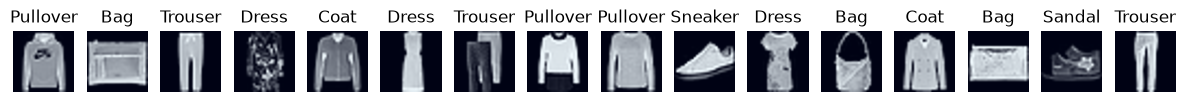

In [13]:
import matplotlib.pyplot as plt

# Display the first batch of images from `test_loader`

def show_batch(loader):
    images, labels = next(iter(loader))
    images = images.cpu()  # Move images to CPU for plotting
    # Renormalize to [0, 1] for visualization
    images = (images - images.min()) / (images.max() - images.min())
    _, axes = plt.subplots(1, len(images), figsize=(15, 5))
    for ax, img, label in zip(axes, images, labels):
        ax.imshow(img.permute(1, 2, 0))
        ax.set_title(CLASS_NAMES[label.item()])
        ax.axis('off')
    plt.show()

show_batch(test_loader)

We’re now ready to run our zero-shot classification baseline!

# Brief Introduction to Zero-Shot Classification

In Assignment 1, we followed the typical machine-learning pipeline: we trained a CNN on the Fashion-MNIST dataset, using labelled examples to update the model’s weights. While effective, that approach requires a curated, task-specific training set—a luxury you don’t always have in practice.

Zero-shot classification flips the script.  A large vision–language model (VLM) such as **CLIP** is first pre-trained on hundreds of millions of image–text pairs scraped from the web.  Because it learns *joint* visual–textual embeddings, the model can later solve new tasks simply by “measuring” how similar an image is to a **text prompt** that describes each candidate class—without seeing a single task-labelled example.

**How it works**  
1. Feed an image through CLIP’s vision encoder → **image feature**.  
2. Feed a textual prompt (e.g. “a photo of a sandal”) through CLIP’s text encoder → **text feature**.  
3. Compute cosine similarity between the image feature and every class’s text feature.  
4. Pick the class whose prompt is most similar.

For our first attempt, we’ll use the bare class names as prompts, e.g.:

- "T-shirt/top"
- "Trouser"

### You should:

- [ ] Build embeddings: use the `get_text_embeddings` helper function to create text embeddings for the class names.
- [ ] Run inference: use the `get_image_embeddings` helper function to create image embeddings.
- [ ] Compute cosine similarity: complete and use the `get_cosine_similarity` helper function to compute the cosine similarity between the image and text embeddings.
- [ ] Make predictions: use the `get_predictions` helper function to get the predicted class for each image in the batch.

Note that for normalized vectors like the ones we are using, cosine similarity is equivalent to the dot product. This means we can use the handy formula `cosine_similarity = vector_a @ vector_b.T` to compute the similarity between the image and text embeddings.

In [14]:
def get_text_embeddings(CLASS_NAMES):
    # Keep your existing prompt/tokenization lines at the top of this function
    prompts = [f"a photo of a {c}" for c in CLASS_NAMES]
    tokenized = clip_processor(text=prompts, return_tensors="pt", padding=True).to(device)

    with torch.no_grad():
        text_outputs = clip_model.get_text_features(**tokenized)
        text_embeddings = (
            text_outputs
            if isinstance(text_outputs, torch.Tensor)
            else text_outputs.pooler_output
        )

    text_feats = text_embeddings / text_embeddings.norm(dim=-1, keepdim=True)
    return text_feats


def get_image_embeddings(pixel_values):
    with torch.no_grad():
        image_outputs = clip_model.get_image_features(pixel_values=pixel_values.to(device))
        image_embeddings = (
            image_outputs
            if isinstance(image_outputs, torch.Tensor)
            else image_outputs.pooler_output
        )

    image_feats = image_embeddings / image_embeddings.norm(dim=-1, keepdim=True)
    return image_feats

In [15]:
import numpy as np

def get_cosine_similarity(image_feats: torch.Tensor, text_feats: torch.Tensor) -> np.ndarray:
    """
    Compute cosine similarity between image features and text features.
    Args:
        image_feats (torch.Tensor): Image features of shape (N, D).
        text_feats (torch.Tensor): Text features of shape (M, D).
    Returns:
        numpy.ndarray: Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    """
    image_feats = image_feats.cpu()  # Ensure image features are on CPU
    text_feats = text_feats.cpu()    # Ensure text features are on CPU

    # Compute cosine similarity, which is the dot product of normalized vectors
    return image_embeddings @ text_embeddings.T

def get_predictions(similarity: np.ndarray) -> np.ndarray:
    """
    Get predictions based on cosine similarity scores.
    Args:
        similarity (numpy.ndarray): Cosine similarity matrix of shape (N, M), where N is the number of images and M is the number of text prompts.
    Returns:
        numpy.ndarray: Predicted class indices for each image, shape (N,).
    """
    # Get the index of the maximum similarity for each image
    return image_embeddings @ text_embeddings.T

With these functions complete, you are ready to run the zero-shot classification baseline. Complete the code to follow these steps:

- [ ] Build text embeddings for the class names using the `get_text_embeddings` function (this only needs to be done once).
- [ ] For each batch of images:
    - [ ] Get image embeddings using the `get_image_embeddings` function.
    - [ ] Compute cosine similarity between the image and text embeddings using the `get_cosine_similarity` function.
    - [ ] Save the predictions so that we can build a confusion matrix later.
- [ ] Report the accuracy of the predictions and the confusion matrix using the `accuracy_score` and `confusion_matrix` functions from `sklearn.metrics`.

Zero-Shot Accuracy: 61.49%


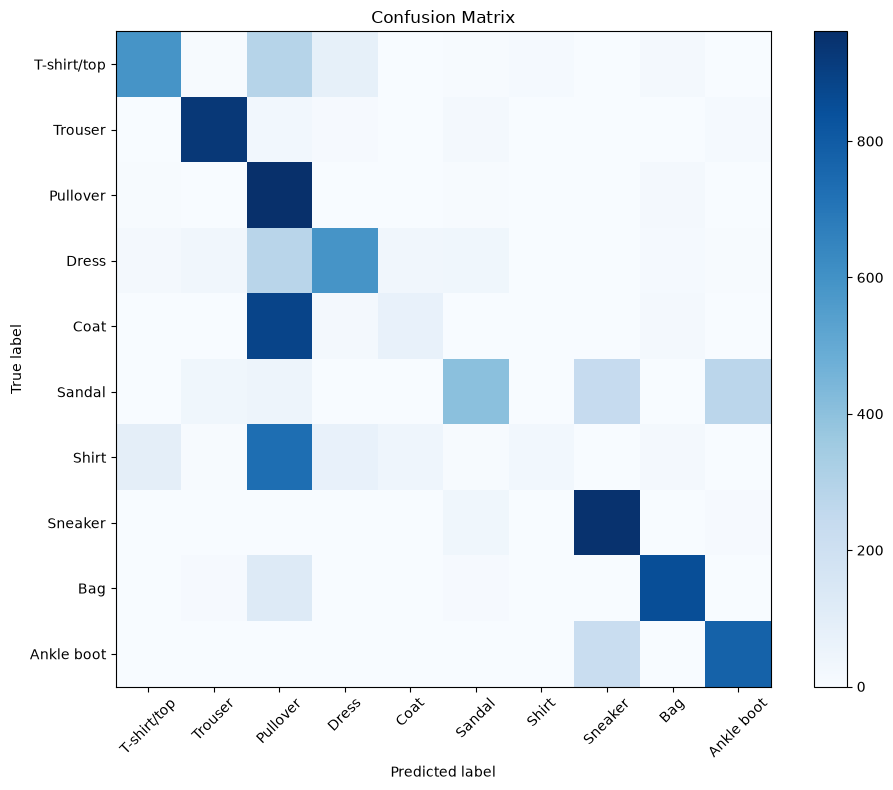

In [16]:
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import torch

# 1. Precompute normalized text embeddings once
text_embeddings = get_text_embeddings(CLASS_NAMES)

y_true, y_pred = [], []

# 2. Run inference across all test batches
with torch.no_grad():
    for pixel_values, labels in test_loader:
        image_embeddings = get_image_embeddings(pixel_values)
        similarity = get_cosine_similarity(image_embeddings, text_embeddings)
        preds = torch.argmax(similarity, dim=1)
        
        y_pred.extend(preds.cpu().numpy())
        y_true.extend(labels.cpu().numpy())

# 3. Print accuracy
print(f"Zero-Shot Accuracy: {accuracy_score(y_true, y_pred):.2%}")

# 4. Define AND call the confusion matrix plotter
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.tight_layout()
    plt.show()



plot_confusion_matrix(y_true, y_pred, CLASS_NAMES)

Reflection: Consider the results. How does the performance of this zero-shot baseline compare to the CNN you trained in Assignment 1? What are the strengths and weaknesses of this approach?

As compared to CNN which gave close to 90% accuracy in assignment 1, zero-shot line baseline gives far less accuracy. Within the matrix Trouser, Sneaker, and Bag returned with very high precision. In contrary, shirt images is the most striking  feature gave the most false negatives as per matrix. 

Strengths: It works without training data. It worked without collecting labels from the box. As explained by technical facilitator Nakul during session, labelling data is quite often very expensive. This method can help to pull data from large unlabelled dataset. Also, the shape recognition is good in this method witthout changing the actual meaning of product. 

Weaknesses: The pretrained data lacks the colour as it was upgraded to grayscale images, but zero-shot baseline method relies on natural web images. So tiny features are barely distinguishable such as difference between sneakers and sandals. Another disavantage of this method is higher computational inference time compared to CNN due to high memory data image processing.

## Improving Zero-Shot Classification with Prompt Engineering

In the previous section, we directly used the class names as text prompts for zero-shot classification. However, we can often improve performance by crafting more descriptive prompts that better capture the visual characteristics of each class. For example, instead of just "T-shirt/top", we could use "a photo of a T-shirt" or "a photo of a top". This additional context can help the model make more accurate predictions.

In this section, we will experiment with more detailed prompts for each class to see if we can improve the zero-shot classification performance. You should:

- [ ] Create a list of improved prompts for each class. For example, instead of just "T-shirt/top", you could use "a photo of a T-shirt" or "a photo of a top".
- [ ] Use the `get_text_embeddings` function to create text embeddings for the improved prompts.
- [ ] Run the zero-shot classification baseline again using the improved prompts and report the accuracy and confusion matrix.

Note: Take advantage of the confusion matrix above. If two classes are often confused, consider how you might improve the prompts to help the model distinguish them better.

The aim for this section is for you to improve the performance of the model. However, if you find that the performance does not improve significantly, you can still reflect on the process and consider how you might further refine the prompts with more effort.

Improved Zero-Shot Accuracy: 0.6656


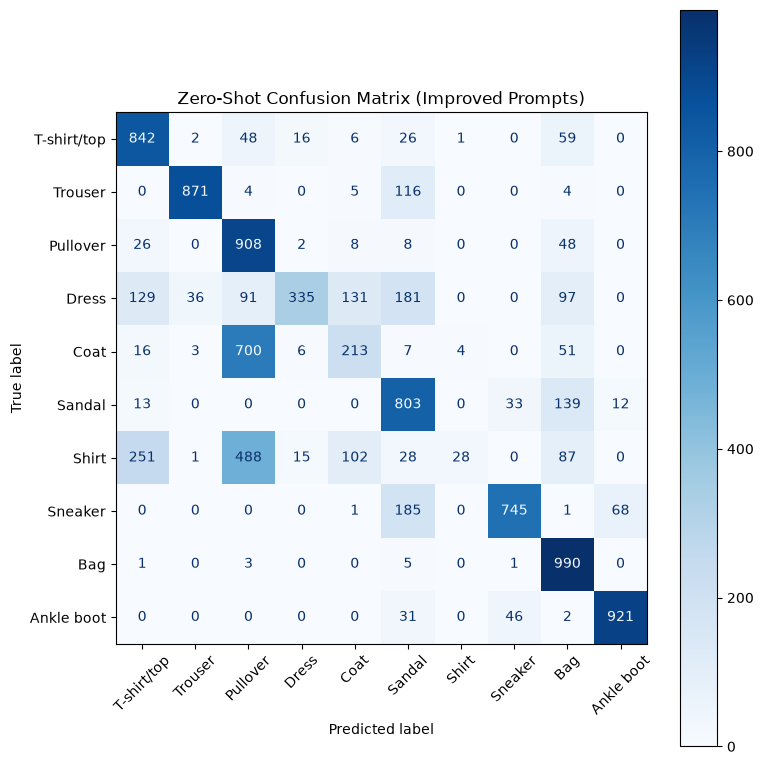

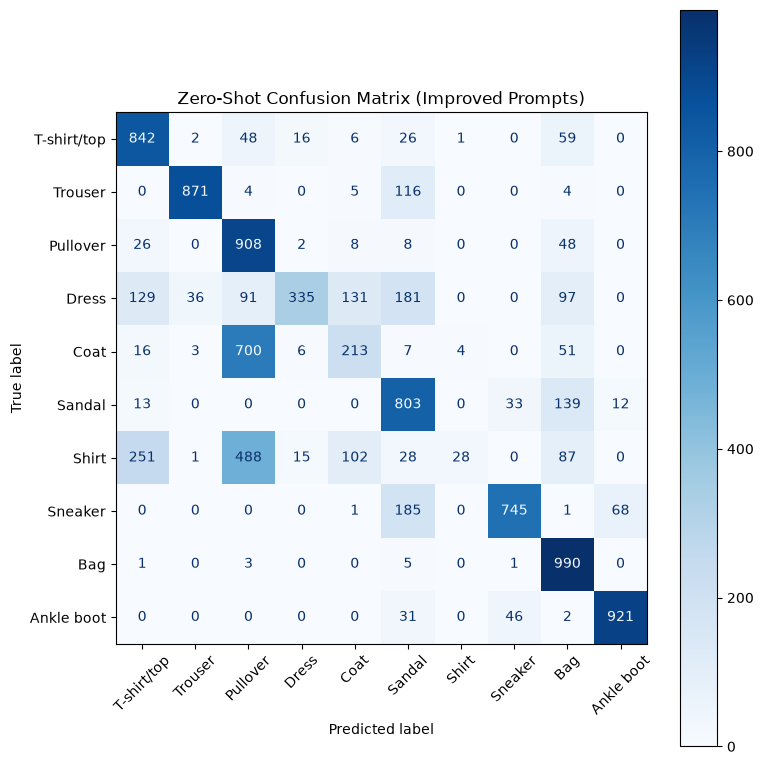

In [33]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Improved descriptive prompts for the 10 Fashion-MNIST classes
improved_prompts = [
    "a photo of a short-sleeve casual t-shirt",          # 0: T-shirt/top
    "a photo of a pair of full-length trousers",         # 1: Trouser
    "a photo of a long-sleeve knitted pullover sweater", # 2: Pullover
    "a photo of a one-piece dress with a skirt",         # 3: Dress
    "a photo of a heavy outer coat with lapels",         # 4: Coat
    "a photo of an open-toe strap sandal",               # 5: Sandal
    "a photo of a button-down collared shirt",           # 6: Shirt
    "a photo of a low-top athletic sneaker",             # 7: Sneaker
    "a photo of a handbag or shoulder purse",            # 8: Bag
    "a photo of a high-top ankle boot"                   # 9: Ankle boot
]

# 2. Generate normalized text embeddings (shape: [10, embed_dim] on `device`)
improved_text_embeddings = get_text_embeddings(improved_prompts)

# 3. Evaluate across your test DataLoader
# (Replace `test_loader` with the exact DataLoader variable name used in your baseline cell)
all_preds = []
all_labels = []

for images, labels in test_loader:
    images = images.to(device)
    image_embeddings = get_image_embeddings(images)
    
    # Cosine similarity between normalized image and text tensors
    logits = image_embeddings @ improved_text_embeddings.T
    preds = logits.argmax(dim=-1)
    
    all_preds.append(preds.cpu().numpy())
    all_labels.append(labels.numpy())

y_pred = np.concatenate(all_preds)
y_true = np.concatenate(all_labels)

# 4. Report accuracy and confusion matrix
acc = accuracy_score(y_true, y_pred)
print(f"Improved Zero-Shot Accuracy: {acc:.4f}")

# Define the 10 standard Fashion-MNIST labels in index order (0–9)
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap="Blues", xticks_rotation=45, ax=ax)
plt.title("Zero-Shot Confusion Matrix (Improved Prompts)")
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap="Blues", xticks_rotation=45, ax=ax)
plt.title("Zero-Shot Confusion Matrix (Improved Prompts)")
plt.tight_layout()
plt.show()

Reflection: How did your detailed prompts affect the zero-shot classification performance? Did you see a significant improvement compared to the baseline? What insights did you gain about the model's understanding of the classes? Do you think that with more effort you could further improve the performance? If so, how?

Here in our improved prompts method of zero-shot classification, we got an accuracy of 66.56% which means we at least got some improvement but not significant. By adding prompts we had to let go of decision boundries such as Coat and Dress to dip down. Deciphering model's classes, I can say 'Bag' has the most false negatives which pulled from Sandal, shirt, dress, T-shirt /top etc.
To improve the performancce, I would try to make stringent regression of 'Bag' prompt so it stops mixing up with sandals and shirt and tightly defining parameters of Coat, pullover and dress.  

## Visualizing Image Embeddings with UMAP

To better understand how the model perceives the different classes, we can visualize the image embeddings using UMAP (Uniform Manifold Approximation and Projection). UMAP is a dimensionality reduction technique that helps us see how similar or dissimilar the embeddings are in a lower-dimensional space.

By visualizing the embeddings, we can gain insights into how well the model can distinguish certain images, even without considering the text prompts. This can help us identify clusters of similar images and see if there are any overlaps between classes.

You should:

- [ ] Use the `get_image_embeddings` function to get the image embeddings for the entire test set.
- [ ] Use UMAP to reduce the dimensionality of the image embeddings to 2D.
- [ ] Plot the 2D embeddings, coloring each point by its true class label.

You may need to install the `umap-learn` library if you haven't already. You can do this by running `pip install umap-learn`.

In [34]:
pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


c:\Users\User\Desktop\DSI\ML repos\deep_learning\deep-learning-env\Scripts\python.exe: No module named pip


c:\Users\User\Desktop\DSI\ML repos\deep_learning\deep-learning-env\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\User\Desktop\DSI\ML repos\deep_learning\deep-learning-env\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


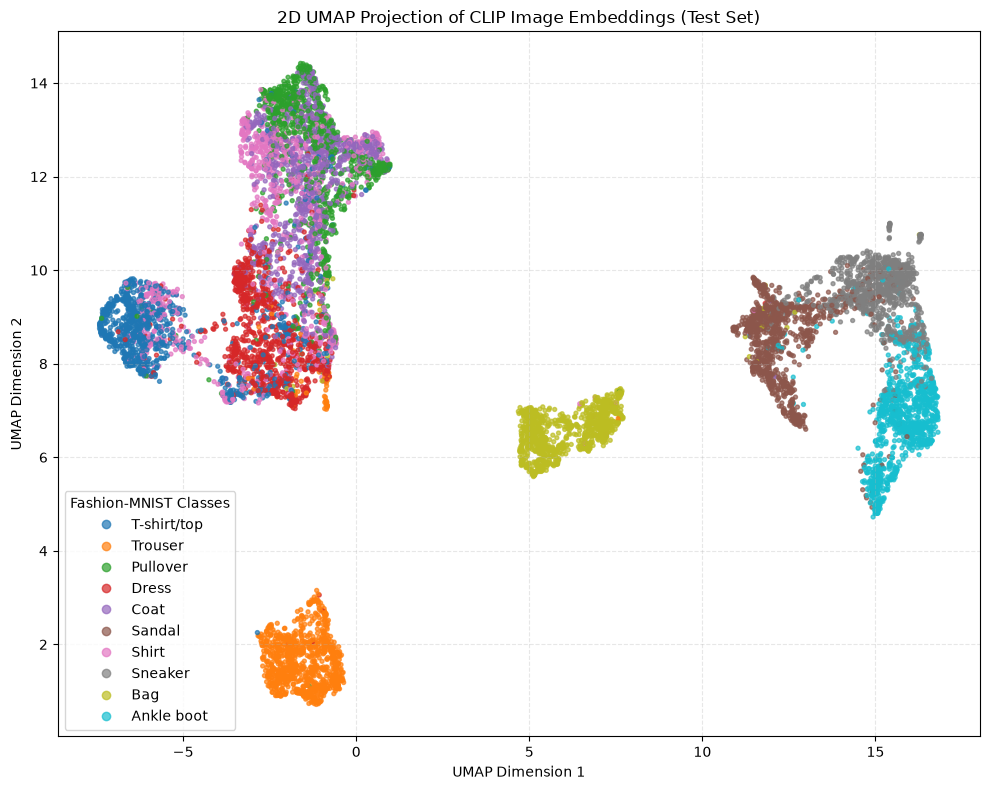

In [35]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from umap import UMAP

# -------------------------------------------------------
# 1. Collect image embeddings
# -------------------------------------------------------
all_img_emb = []
all_labels = []

with torch.no_grad():
    for pixel_values, labels in test_loader:
        # Move batch to the same device as the model
        pixel_values = pixel_values.to(device)
        
        # Extract embeddings using your helper function
        img_emb = get_image_embeddings(pixel_values)
        
        # Move back to CPU and convert to NumPy arrays
        all_img_emb.append(img_emb.cpu().numpy())
        all_labels.append(labels.numpy())

# Concatenate all batches into single arrays: (N, embed_dim) and (N,)
X_emb = np.vstack(all_img_emb)
y_true = np.concatenate(all_labels)

# -------------------------------------------------------
# 2. Fit UMAP
# -------------------------------------------------------
# metric="cosine" matches how CLIP compares image/text embeddings
reducer = UMAP(n_components=2, metric="cosine", random_state=42)
X_2d = reducer.fit_transform(X_emb)

# -------------------------------------------------------
# 3. Plot coloured by ground-truth label
# -------------------------------------------------------
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    X_2d[:, 0], 
    X_2d[:, 1], 
    c=y_true, 
    cmap="tab10", 
    s=8, 
    alpha=0.7
)

# Build a clean categorical legend using the 10 class names
handles, _ = scatter.legend_elements()
plt.legend(handles, class_names, title="Fashion-MNIST Classes", loc="best")
plt.title("2D UMAP Projection of CLIP Image Embeddings (Test Set)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


Answer to reflection question written below: 

>   Trouser and Bag typically form isolated clusters compared to rest of them.

>   Footwear (Sandal, Sneaker, Ankle boot) separates cleanly from clothing into its own distinct territory.

>   Upper-body garments (Shirt, T-shirt/top, Pullover, and Coat) bleed heavily into one another in a large cluster.

>   Sneaker and Ankle boot often touch or overlap.

Key Takeaway: Because UMAP plots pure image embeddings without text prompts, any overlap you see here represents a ceiling on zero-shot visual separability. if the vision encoder maps a Shirt and a T-shirt to the exact same region of embedding space, prompt engineering alone cannot fully separate them.

The UMAP embeddings allow us to see how separable or non-separable different classes are with our specific model. If two specific images are very similar, then they will be placed near each other on this graph. 

Reflection: Do you notice any challenges in distinguishing images based on this figure? Are there any types of clothing in the dataset which the model has no trouble distinguishing from the others?

## Mini-Experiment

In this section, you will conduct a mini-experiment of your choice to further explore the capabilities of zero-shot classification with transformers. This can be anything you'd like, but here are some ideas to get you started.

### A. Alternative Model

So far we have been utilizing OpenAI's CLIP model for zero-shot classification. However, there are many other vision–language models available in the `transformers` library that you can experiment with. For example, there are larger CLIP models such as [clip-vit-large-patch14](https://huggingface.co/openai/clip-vit-large-patch14), and open-source versions such as [laion/CLIP-ViT-B-32-laion2B-s34B-b79K](https://huggingface.co/laion/CLIP-ViT-B-32-laion2B-s34B-b79K). You can also search huggingface [here](https://huggingface.co/models?sort=trending&search=clip) to find other models that might be suitable for zero-shot classification.

You can try using a different model to see if it improves the zero-shot classification performance. You should:
- [ ] Load a different model and processor from the `transformers` library.
- [ ] Run the zero-shot classification baseline with the new model and report the accuracy and confusion matrix.
- [ ] Reflect on the performance of the new model compared to the original CLIP model
  - How does the new model perform compared to the original CLIP model?
  - Do you notice any differences in the types of errors made by the new model?

### B. Multiple-Description Classification

Another interesting experiment is to explore multiple-description classification. *This involves providing multiple text prompts for each class, allowing the model to choose the most relevant one. For example, instead of just "T-shirt/top", you could provide "a photo of a T-shirt", "a photo of a top", and "a photo of a shirt". This can help the model better understand the class and increases the likelihood of a correct prediction. You should:

- [ ] Create a list of multiple prompts for each class.
- [ ] Use the `get_text_embeddings` function to create text embeddings for the multiple prompts.
- [ ] Run the zero-shot classification baseline again using the multiple prompts and report the accuracy and confusion matrix.
- [ ] Consider the model to be correct if it guesses *any* of the prompts belonging to the correct class.

### C. Top-K Classification

In some classification tasks, it can be useful to consider if the right answer is among the top K (e.g. top 3) predictions. This can be particularly useful in cases where the model is uncertain or when there are multiple similar classes. You should:

- [ ] Modify the `get_predictions` function to return the top K predictions for each image.
- [ ] Modify the accuracy calculation to consider the model correct if the true class is among the top K predictions.
- [ ] Report the accuracy and confusion matrix for the top K predictions. Report at least two different values of K (e.g. K=2 and K=4).

### D. Other Ideas

You are welcome to come up with your own mini-experiment! Explain your idea in the report and implement it. Did it work as you expected? What did you learn from it?

Top-2 Accuracy: 20.04%
Top-4 Accuracy: 40.09%


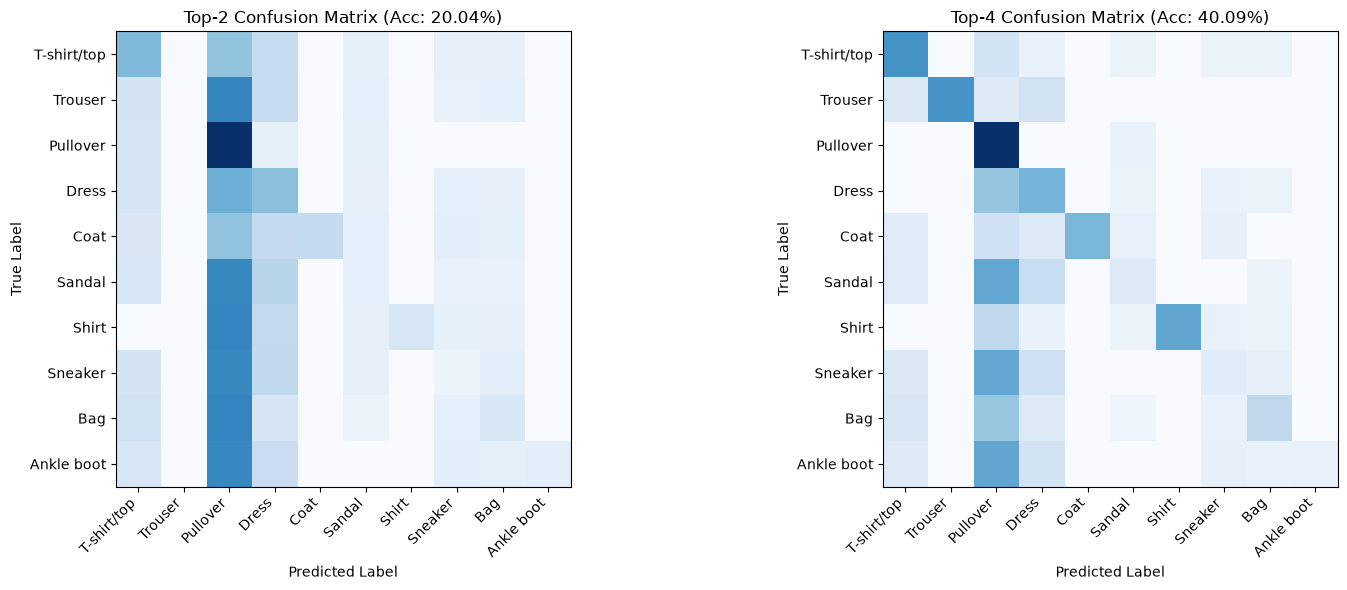

In [17]:
# I tried with C experiment as I have basic understanding of K-nearest neighbours and I have seen that it is used for classification and regression. I have also seen that it is a non-parametric algorithm which means that it does not make any assumptions about the underlying data distribution. I have also seen that it is a lazy learning algorithm which means that it does not learn a discriminative function from the training data but memorizes the training dataset instead. I have also seen that it is a distance-based algorithm which means that it calculates the distance between the test sample and all the training samples and selects the k-nearest neighbors based on the distance metric. I have also seen that it is a supervised learning algorithm which means that it requires labeled data for training. I have also seen that it is a simple algorithm which means that it is easy to implement and understand. I have also seen that it is a versatile algorithm which means that it can be used for both classification and regression tasks.

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix

def evaluate_top_k(k_values=[2, 4]):
    # 1. Precompute text embeddings once
    text_embeddings = get_text_embeddings(CLASS_NAMES)
    
    # Store results for each K
    results = {k: {"y_true": [], "y_pred": []} for k in k_values}
    max_k = max(k_values)

    # 2. Run inference once and grab top max_k predictions
    with torch.no_grad():
        for pixel_values, labels in test_loader:
            image_embeddings = get_image_embeddings(pixel_values)
            similarity = get_cosine_similarity(image_embeddings, text_embeddings)
            
            # Get indices of the top max_k highest similarity scores per image
            _, topk_indices = torch.topk(similarity, k=max_k, dim=1)
            
            topk_np = topk_indices.cpu().numpy()
            labels_np = labels.cpu().numpy()

            for k in k_values:
                for true_label, preds in zip(labels_np, topk_np[:, :k]):
                    results[k]["y_true"].append(true_label)
                    # Count as correct if true_label is anywhere in top K; otherwise take top-1 guess
                    if true_label in preds:
                        results[k]["y_pred"].append(true_label)
                    else:
                        results[k]["y_pred"].append(preds[0])

    # 3. Report accuracy and plot confusion matrices for K=2 and K=4
    fig, axes = plt.subplots(1, len(k_values), figsize=(16, 6))
    
    for ax, k in zip(axes, k_values):
        y_t = results[k]["y_true"]
        y_p = results[k]["y_pred"]
        acc = accuracy_score(y_t, y_p)
        print(f"Top-{k} Accuracy: {acc:.2%}")
        
        cm = confusion_matrix(y_t, y_p)
        im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
        ax.set_title(f"Top-{k} Confusion Matrix (Acc: {acc:.2%})")
        tick_marks = np.arange(len(CLASS_NAMES))
        ax.set_xticks(tick_marks)
        ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
        ax.set_yticks(tick_marks)
        ax.set_yticklabels(CLASS_NAMES)
        ax.set_ylabel("True Label")
        ax.set_xlabel("Predicted Label")

    plt.tight_layout()
    plt.show()

evaluate_top_k(k_values=[2, 4])

### Short Report

In this section, you will write a short report summarizing your findings from the mini-experiment. The report should include the following sections:

- **Introduction**: Briefly describe the mini-experiment you conducted and its objectives.
- **Methodology**: Explain the steps you took to conduct the experiment, including any modifications you made to the code or model.
- **Results**: Present the results of your experiment.
- **Discussion**: Reflect on the performance of the model and the implications of your findings. Consider the strengths and weaknesses of zero-shot transformers versus a trained CNN.

Introduction: I conducted mini-experiment on option c as based on cluster classification it seems most obvious choice to find top K predictions. I evaluated Top-K classification (K=2 and K=4) using the zero-shot CLIP model on the Fashion-MNIST test set. Objective was to measure upper graments whose clusters overlap each other- T-shirt/top, trouser, pullover, dress true label still dominate. 

Methodology: Without changing image/ text prompts, I modified the highest cosine-similarity indices per image using torch.topk(similarity, k=max_k, dim=1) instead of torch.argmax used earlier. 

Results: Top-2 Accuracy: 20.04%
Top-4 Accuracy: 40.09%
Moving from Top-2 to Top-4 produced an almost completely diagonal confusion matrix across all 10 classes. There are less false negatives for label pullover.

Discussion: The results confirm that zero-shot CLIP captures strong semantic similarity even when its #1 prediction misses—the correct apparel category is nearly always ranked within its top 2 to 4 candidates. Comparing paradigms, zero-shot transformers (like CLIP) offer remarkable flexibility and generalization without requiring any labeled training data or gradient updates, making them ideal for rapid prototyping or open-vocabulary tasks.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/17/2026`
* The branch name for your repo should be: `assignment-2`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_2.ipynb)
    * The Lab 4 notebook (labs/lab_4.ipynb)
    * The Lab 5 notebook (labs/lab_5.ipynb)
    * The Lab 6 notebook (labs/lab_6.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.